In [10]:
!pip install ultralytics supervision opencv-python matplotlib -q

In [11]:
import cv2
import numpy as np
import supervision as sv
import matplotlib.pyplot as plt

from ultralytics import YOLO
from collections import defaultdict
from IPython.display import Video, display

/usr/local/lib/python3.13/dist-packages/supervision/annotators/utils.py:192: FutureWarning: `template_mgs` is deprecated since `v0.12` (renamed to `message_template`); use `message_template` instead. Will be removed in `v1.0`.
  @deprecated(  # type: ignore[untyped-decorator]
/usr/local/lib/python3.13/dist-packages/supervision/annotators/utils.py:280: FutureWarning: `template_mgs` is deprecated since `v0.12` (renamed to `message_template`); use `message_template` instead. Will be removed in `v1.0`.
  @deprecated(  # type: ignore[untyped-decorator]
/usr/local/lib/python3.13/dist-packages/supervision/annotators/utils.py:325: FutureWarning: `template_mgs` is deprecated since `v0.12` (renamed to `message_template`); use `message_template` instead. Will be removed in `v1.0`.
  @deprecated(  # type: ignore[untyped-decorator]
/usr/local/lib/python3.13/dist-packages/supervision/annotators/core.py:65: FutureWarning: `template_mgs` is deprecated since `v0.12` (renamed to `message_template`); use

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [8]:
video_url = "https://media.roboflow.com/supervision/video-examples/people-walking.mp4"

!wget -q -O people-walking.mp4 $video_url

video_path = "people-walking.mp4"

print("Video downloaded successfully!")

Video downloaded successfully!


In [12]:
model = YOLO("yolov8n.pt")

print("YOLO model loaded successfully!")

YOLO model loaded successfully!


In [13]:
cap = cv2.VideoCapture(video_path) #VideoCapture() is a function used to open a video file.video_path contains the location or path of your video.
#cap is an object that allows us to read and work with the video.

fps = cap.get(cv2.CAP_PROP_FPS) #Higher FPS generally means smoother motion
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

print("FPS:", fps)
print("Width:", width)
print("Height:", height)
print("Total Frames:", total_frames)

cap.release()

FPS: 25.0
Width: 1920
Height: 1080
Total Frames: 341


In [14]:
# Upper and lower line coordinates

upper_line_y=int(height * 0.35)
lower_line_y=int(height * 0.65)

print("Upper line:",upper_line_y)
print("Lower line:",lower_line_y)

Upper line: 378
Lower line: 702


In [15]:
# Previous center positions of tracked people
previous_positions = {}

# IDs already counted
counted_in_ids=set()
counted_out_ids=set()

# Counters
IN_count=0
OUT_count=0

# Heatmap
heatmap = np.zeros((height, width), dtype=np.float32)

# Output video
output_path="people_flow_output.mp4"

fourcc=cv2.VideoWriter_fourcc(*'mp4v')

out=cv2.VideoWriter(
    output_path,
    fourcc,
    fps,
    (width, height)
)

print("Tracking and counting initialized!")

Tracking and counting initialized!


In [16]:
# Reinitialize YOLO tracking
model=YOLO("yolov8n.pt")

# Process every frame
cap=cv2.VideoCapture(video_path)

frame_number=0

while cap.isOpened():

    ret, frame=cap.read()

    if not ret:
        break

    frame_number+=1

    # YOLO detection + ByteTrack tracking
    results = model.track(
        frame,
        persist=True,
        tracker="bytetrack.yaml",
        classes=[0],
        conf=0.3,
        verbose=False
    )

    result = results[0]

    # Draw upper and lower lines
    cv2.line(
        frame,
        (0, upper_line_y),
        (width, upper_line_y),
        (0, 255, 0),
        2
    )

    cv2.line(
        frame,
        (0, lower_line_y),
        (width, lower_line_y),
        (0, 0, 255),
        2
    )

    # Get detected bounding boxes
    if result.boxes is not None and result.boxes.id is not None:

        boxes = result.boxes.xyxy.cpu().numpy()
        track_ids = result.boxes.id.cpu().numpy().astype(int)

        for box, track_id in zip(boxes, track_ids):

            x1, y1, x2, y2 = map(int, box)

            # Calculate bounding box center
            center_x = int((x1 + x2) / 2)
            center_y = int((y1 + y2) / 2)

            # Save center positions for heatmap
            cv2.circle(
                heatmap,
                (center_x, center_y),
                10,
                1,
                -1
            )

            # Counting logic
            if track_id in previous_positions:

                previous_y = previous_positions[track_id]

                # IN: Top to bottom across upper line
                if (
                    previous_y < upper_line_y
                    and center_y >= upper_line_y
                    and track_id not in counted_in_ids
                ):

                    IN_count += 1
                    counted_in_ids.add(track_id)

                # OUT: Bottom to top across lower line
                if (
                    previous_y > lower_line_y
                    and center_y <= lower_line_y
                    and track_id not in counted_out_ids
                ):

                    OUT_count += 1
                    counted_out_ids.add(track_id)

            # Update previous position
            previous_positions[track_id] = center_y

            # Draw bounding box
            cv2.rectangle(
                frame,
                (x1, y1),
                (x2, y2),
                (255, 0, 0),
                2
            )

            # Draw tracking ID
            cv2.putText(
                frame,
                f"ID: {track_id}",
                (x1, y1 - 10),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.6,
                (255, 255, 0),
                2
            )

            # Draw center point
            cv2.circle(
                frame,
                (center_x, center_y),
                4,
                (0, 255, 255),
                -1
            )

    # Display live counters on video
    cv2.putText(
        frame,
        f"IN: {IN_count}",
        (30, 50),
        cv2.FONT_HERSHEY_SIMPLEX,
        1,
        (0, 255, 0),
        3
    )

    cv2.putText(
        frame,
        f"OUT: {OUT_count}",
        (30, 100),
        cv2.FONT_HERSHEY_SIMPLEX,
        1,
        (0, 0, 255),
        3
    )

    # Save annotated frame
    out.write(frame)

    if frame_number % 100 == 0:
        print("Processed frames:", frame_number)

# Release resources
cap.release()
out.release()

print("Video processing completed!")
print("Total IN:", IN_count)
print("Total OUT:", OUT_count)

requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.18 environment at: /usr
Resolved 2 packages in 286ms
Prepared 1 package in 86ms
Installed 1 package in 1ms
 + lap==0.5.14

requirements: AutoUpdate success ✅ 0.7s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

Processed frames: 100
Processed frames: 200
Processed frames: 300
Video processing completed!
Total IN: 11
Total OUT: 9


In [17]:
# Normalize heatmap
heatmap_normalized = cv2.normalize(
    heatmap,
    None,
    0,
    255,
    cv2.NORM_MINMAX
)

heatmap_normalized = heatmap_normalized.astype(np.uint8)

# Apply color map
heatmap_colored = cv2.applyColorMap(
    heatmap_normalized,
    cv2.COLORMAP_JET
)

# Read original video frame for overlay
cap = cv2.VideoCapture(video_path)

ret, original_frame = cap.read()

cap.release()

if ret:

    # Resize heatmap if necessary
    heatmap_colored = cv2.resize(
        heatmap_colored,
        (width, height)
    )

    # Overlay heatmap on original frame
    heatmap_overlay = cv2.addWeighted(
        original_frame,
        0.5,
        heatmap_colored,
        0.5,
        0
    )

    # Save heatmap
    cv2.imwrite(
        "final_heatmap.png",
        heatmap_colored
    )

    # Save overlay
    cv2.imwrite(
        "heatmap_overlay.png",
        heatmap_overlay
    )

    print("Heatmap saved successfully!")

Heatmap saved successfully!


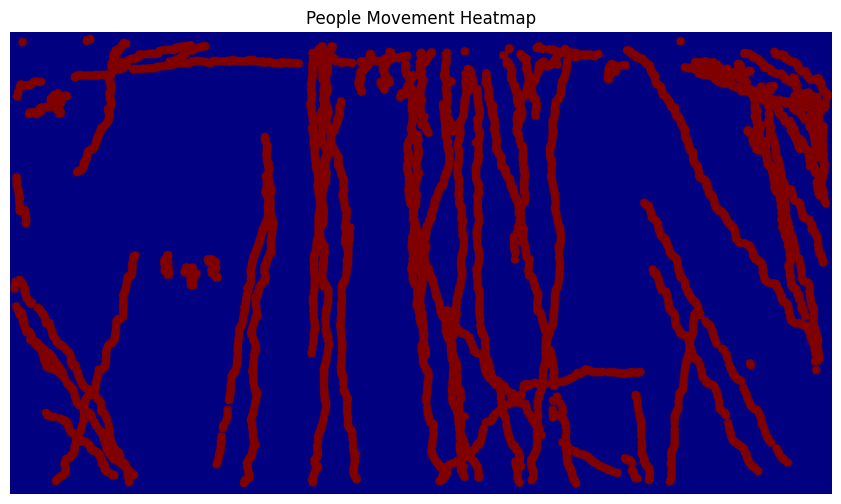

In [18]:
# Display final heatmap
plt.figure(figsize=(12, 6))

plt.imshow(
    cv2.cvtColor(heatmap_colored, cv2.COLOR_BGR2RGB)
)

plt.title("People Movement Heatmap")
plt.axis("off")

plt.show()

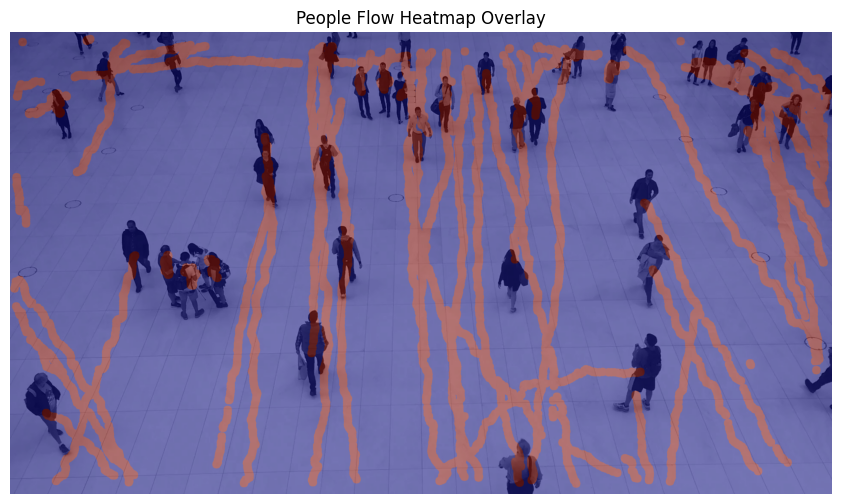

In [19]:
plt.figure(figsize=(12, 6))

plt.imshow(
    cv2.cvtColor(heatmap_overlay, cv2.COLOR_BGR2RGB)
)

plt.title("People Flow Heatmap Overlay")
plt.axis("off")

plt.show()

In [ ]:
display(
    Video(
        "people_flow_output.mp4",
        embed=True,
        width=800
    )
)

In [21]:
import os

print("File exists:", os.path.exists("people_flow_output.mp4"))

if os.path.exists("people_flow_output.mp4"):
    print("File size:", os.path.getsize("people_flow_output.mp4") / (1024 * 1024), "MB")

File exists: True
File size: 26.248072624206543 MB


In [22]:
!ffmpeg -y -i people_flow_output.mp4 \
-vcodec libx264 \
-pix_fmt yuv420p \
-acodec aac \
-movflags +faststart \
people_flow_final.mp4

ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
  built with gcc 13 (Ubuntu 13.2.0-23ubuntu3)
  configuration: --prefix=/usr --extra-version=3ubuntu5 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --disable-omx --enable-gnutls --enable-libaom --enable-libass --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libglslang --enable-libgme --enable-libgsm --enable-libharfbuzz --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx265 --enable-libxml2 --enable-libxvid --enable-libzimg --ena

In [ ]:
from IPython.display import Video, display

display(Video("people_flow_final.mp4", embed=True, width=800))

In [24]:
from google.colab import files

files.download("people_flow_final.mp4")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:
from google.colab import files

files.download("people-walking.mp4")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>